# Read Data and Its Paths

In [12]:
from pathlib import Path

DATA_DIR = Path("episode_2")

# Images (sorted by filename, which starts with a frame index and timestamp).
# Files starting with "._" are macOS metadata copies, not real images, so skip them.
def list_images(folder):
    return sorted(p for p in folder.glob("*.jpg") if not p.name.startswith("._"))

rgb_paths = list_images(DATA_DIR / "images" / "rgb")
thermal_paths = list_images(DATA_DIR / "images" / "thermal")

# Sensor logs
imu_log_path = DATA_DIR / "imu_log.csv"
gnss_log_path = DATA_DIR / "gnss_log.csv"
camera_log_path = DATA_DIR / "camera_log.csv"

print(f"RGB images:     {len(rgb_paths)}")
print(f"Thermal images: {len(thermal_paths)}")
print(f"IMU log:        {imu_log_path} (exists: {imu_log_path.exists()})")
print(f"GNSS log:       {gnss_log_path} (exists: {gnss_log_path.exists()})")
print(f"Camera log:     {camera_log_path} (exists: {camera_log_path.exists()})")

RGB images:     5742
Thermal images: 5742
IMU log:        episode_2/imu_log.csv (exists: True)
GNSS log:       episode_2/gnss_log.csv (exists: True)
Camera log:     episode_2/camera_log.csv (exists: True)


# Data Analysis

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

NS = 1e9  # nanoseconds per second

# ---- Load the three logs --------------------------------------------------
imu = pd.read_csv(imu_log_path)
gnss = pd.read_csv(gnss_log_path)
cam = pd.read_csv(camera_log_path)

# Every sensor has its own name for the timestamp column. Give them all the same name
# ("t_ns") so the later steps can treat them identically.
imu = imu.rename(columns={"timestamp_ns": "t_ns"})
gnss = gnss.rename(columns={"timestamp_ns": "t_ns"})
cam = cam.rename(columns={"image_stamp_ns": "t_ns"})

print("Rows loaded -> IMU:", len(imu), "| GNSS:", len(gnss), "| camera:", len(cam))

Rows loaded -> IMU: 74687 | GNSS: 2989 | camera: 5742


In [14]:
# ---- Drop columns that carry no information --------------------------------
# A column with a single unique value (e.g. all covariances = 0, frame_id = "imu_link")
# tells us nothing, so remove it.
def drop_constant_columns(df, name):
    constant = [c for c in df.columns if df[c].nunique() <= 1]
    print(f"{name}: dropping {len(constant)} constant columns")
    return df.drop(columns=constant)

imu = drop_constant_columns(imu, "IMU")
gnss = drop_constant_columns(gnss, "GNSS")
cam = drop_constant_columns(cam, "camera")

print("\nIMU columns :", list(imu.columns))
print("GNSS columns:", list(gnss.columns))

IMU: dropping 28 constant columns
GNSS: dropping 9 constant columns
camera: dropping 1 constant columns

IMU columns : ['t_ns', 'timestamp_utc', 'orientation_x', 'orientation_y', 'orientation_z', 'orientation_w', 'angular_velocity_x', 'angular_velocity_y', 'angular_velocity_z', 'linear_acceleration_x', 'linear_acceleration_y', 'linear_acceleration_z']
GNSS columns: ['t_ns', 'timestamp_utc', 'status', 'latitude', 'longitude', 'altitude', 'position_covariance_0', 'position_covariance_4', 'position_covariance_8']


IMU     rows= 74687  span=  979.3 s  median dt=  10.0 ms  backwards steps=3  gaps>50 ms=2
GNSS    rows=  2989  span=  979.0 s  median dt= 250.0 ms  backwards steps=0  gaps>1000 ms=1
camera  rows=  5742  span=  979.2 s  median dt= 199.3 ms  backwards steps=0  gaps>500 ms=0


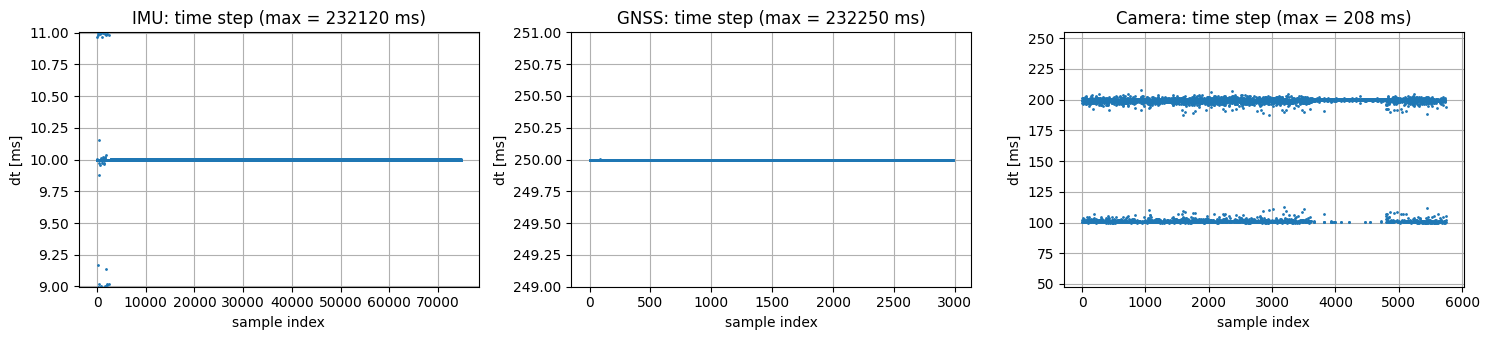

In [15]:
# ---- Check the timestamps of each sensor ------------------------------------
# For a healthy sensor every time step (dt = t[i+1] - t[i]) is positive and close to
# the nominal period. We look for:
#   * backwards steps (dt <= 0): samples that are out of order
#   * large gaps: samples that are missing
def timestamp_report(df, name, gap_ms):
    dt_ms = np.diff(df["t_ns"].values) / 1e6
    span_s = (df["t_ns"].iloc[-1] - df["t_ns"].iloc[0]) / NS
    print(f"{name:7s} rows={len(df):6d}  span={span_s:7.1f} s  "
          f"median dt={np.median(dt_ms):6.1f} ms  "
          f"backwards steps={np.sum(dt_ms <= 0)}  gaps>{gap_ms} ms={np.sum(dt_ms > gap_ms)}")
    return dt_ms

imu_dt = timestamp_report(imu, "IMU", gap_ms=50)
gnss_dt = timestamp_report(gnss, "GNSS", gap_ms=1000)
cam_dt = timestamp_report(cam, "camera", gap_ms=500)

# Plot dt for each sensor. The y-axis is clipped so normal jitter stays visible;
# the huge gaps are annotated in the title instead.
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, dt, name in zip(axes, [imu_dt, gnss_dt, cam_dt], ["IMU", "GNSS", "Camera"]):
    ax.plot(dt, ".", markersize=2)
    lo, hi = np.percentile(dt, [1, 99])
    margin = 0.5 * (hi - lo) + 1
    ax.set_ylim(lo - margin, hi + margin)
    ax.set_title(f"{name}: time step (max = {dt.max():.0f} ms)")
    ax.set_xlabel("sample index")
    ax.set_ylabel("dt [ms]")
plt.tight_layout()
plt.show()

### What the time-step plots show

Each dot is the time between one sample and the next (`dt`). A healthy sensor makes a flat line.

- **IMU (left):** nearly all dots sit on 10 ms, so the IMU runs at 100 Hz. The scattered dots at the far left (first ~2,500 samples) are timestamp glitches: some samples are only a few ms apart and a few jump backwards. The plot is zoomed in, so the huge 232 s gap in the title is not visible here.
- **GNSS (middle):** a perfectly flat line at 250 ms, so 4 Hz. The only problem is the same 232 s gap.
- **Camera (right):** two bands, one near 100 ms and one near 200 ms. The camera is not at a fixed rate. Some frames come 0.1 s apart and others 0.2 s apart, and the average is about 170 ms. There are no gaps, so every frame is accounted for.

**What it means:** the IMU and GNSS are steady except for the glitches at the start and the one long gap. The camera timing is uneven, so later we must interpolate the IMU and GNSS to each frame's own timestamp. We can't assume one frame every 0.2 s.

In [16]:
# ---- Fix the ordering and build a common time axis ---------------------------
# Sort every table by timestamp and remove exact duplicate timestamps, so that
# time always moves forward.
def sort_by_time(df):
    return df.sort_values("t_ns", kind="stable").drop_duplicates("t_ns").reset_index(drop=True)

imu = sort_by_time(imu)
gnss = sort_by_time(gnss)
cam = sort_by_time(cam)

# All three logs use the same clock, so one shared zero point works for all of them:
# the first IMU sample. "t_s" is then time in seconds since the start of the recording.
T0_NS = imu["t_ns"].iloc[0]
for df in (imu, gnss, cam):
    df["t_s"] = (df["t_ns"] - T0_NS) / NS

# GNSS: status -1 means "no fix". Those rows have a meaningless position and a
# covariance of ~1e13, so mark them instead of deleting them.
gnss["has_fix"] = gnss["status"] >= 0
print(f"GNSS rows with a fix: {gnss['has_fix'].sum()} / {len(gnss)}")

# The IMU has a long hole in its timestamps (see the plot above). Find where it is.
imu_gap = imu["t_s"].diff()
big = imu_gap[imu_gap > 1.0]
for idx, gap in big.items():
    print(f"IMU gap: no samples for {gap:.1f} s, from t={imu['t_s'].iloc[idx-1]:.1f} s "
          f"to t={imu['t_s'].iloc[idx]:.1f} s")

GNSS rows with a fix: 2900 / 2989
IMU gap: no samples for 232.1 s, from t=590.9 s to t=823.0 s


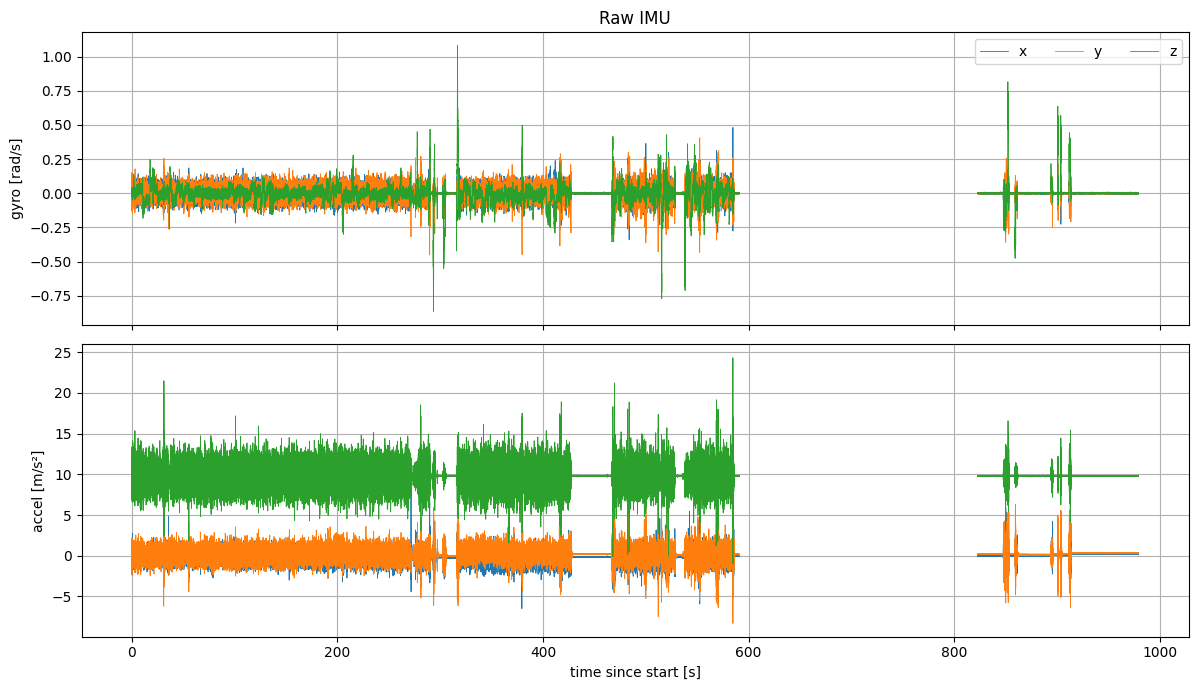

|accel|: median = 9.80 m/s²  (gravity = 9.81)


In [17]:
# ---- Plot the raw IMU signals ------------------------------------------------
# Gyroscope (rotation rate) and accelerometer (specific force) on three axes each.
# NaN is inserted into the gap so the line is not drawn straight across it.
def with_gap_breaks(df, max_gap_s=1.0):
    out = df.copy()
    out.loc[out["t_s"].diff() > max_gap_s, :] = np.nan
    return out

# (the line above blanks the *first row after* each gap, which breaks the line there)
imu_plot = with_gap_breaks(imu)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for axis in "xyz":
    axes[0].plot(imu_plot["t_s"], imu_plot[f"angular_velocity_{axis}"], lw=0.6, label=axis)
    axes[1].plot(imu_plot["t_s"], imu_plot[f"linear_acceleration_{axis}"], lw=0.6, label=axis)
axes[0].set_ylabel("gyro [rad/s]")
axes[1].set_ylabel("accel [m/s²]")
axes[1].set_xlabel("time since start [s]")
axes[0].set_title("Raw IMU")
axes[0].legend(ncol=3)
plt.tight_layout()
plt.show()

# Quick physical sanity check: when the vehicle is not accelerating hard, the length of
# the accel vector should be about 9.81 m/s² (gravity).
accel_norm = np.sqrt((imu[[f"linear_acceleration_{a}" for a in "xyz"]] ** 2).sum(axis=1))
print(f"|accel|: median = {accel_norm.median():.2f} m/s²  (gravity = 9.81)")

### What the raw IMU plot shows

Top: the gyroscope, which measures how fast the sensor is rotating (rad/s). Bottom: the accelerometer, which measures acceleration including gravity (m/s²). The colors are the x, y and z axes.

- **Noisy stretches:** while the vehicle drives (0–430 s, 465–590 s and short bursts after 823 s) both signals are fuzzy. The gyro swings by about ±0.15 rad/s with occasional spikes up to ±0.75 rad/s. The z accelerometer (green) swings around 10 m/s² by about ±5 m/s². This is mostly vibration, bumps and motor noise, not real motion.
- **Flat stretches:** when the vehicle stops, for example around 430–465 s and 920–980 s, the lines collapse to thin flat lines. The gyro sits near 0 and z accel sits near 9.8 m/s², which is gravity. These calm stretches are what we will use to measure the sensor's own noise and bias.
- **The blank gap:** between about 591 s and 823 s there is no IMU data (the 232 s hole). The line is deliberately broken there instead of drawn across it.

**What it means:** the signal is large compared with the sensor's own noise whenever the vehicle moves, so noise must be measured only on the flat, stationary parts. The strong vibration also tells us the IMU is mounted rigidly on a vibrating platform. That is useful to know for filtering later.

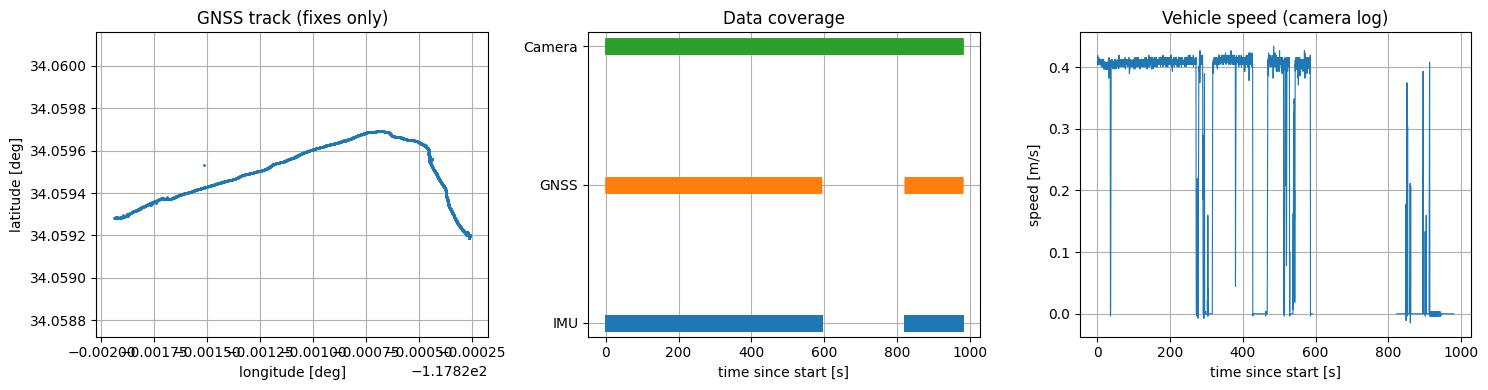

In [18]:
# ---- Plot the GNSS track and the camera timing --------------------------------
fix = gnss[gnss["has_fix"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Where the vehicle went (longitude on x, latitude on y)
axes[0].plot(fix["longitude"], fix["latitude"], ".", markersize=2)
axes[0].set_title("GNSS track (fixes only)")
axes[0].set_xlabel("longitude [deg]")
axes[0].set_ylabel("latitude [deg]")
axes[0].set_aspect("equal", adjustable="datalim")

# 2) When each sensor was recording. A vertical bar = one sample; empty stretches = no data.
for row, (df, name) in enumerate([(imu, "IMU"), (gnss, "GNSS"), (cam, "Camera")]):
    axes[1].plot(df["t_s"], np.full(len(df), row), "|", markersize=12)
axes[1].set_yticks([0, 1, 2])
axes[1].set_yticklabels(["IMU", "GNSS", "Camera"])
axes[1].set_xlabel("time since start [s]")
axes[1].set_title("Data coverage")

# 3) Camera speed over time, to see when the vehicle is moving or stopped
axes[2].plot(cam["t_s"], cam["speed_mps"], lw=0.8)
axes[2].set_title("Vehicle speed (camera log)")
axes[2].set_xlabel("time since start [s]")
axes[2].set_ylabel("speed [m/s]")

plt.tight_layout()
plt.show()

### What the GNSS, coverage and speed plots show

- **GNSS track (left):** the path the vehicle drove, as longitude and latitude from the satellite receiver. It is a smooth curve about 150 m long, running left to right and then turning downward. The one dot off the line near the middle is a bad position reading. Only rows with a fix are drawn.
- **Data coverage (middle):** each bar shows when a sensor was recording. The camera (green) runs the whole time. The GNSS and IMU bars both stop at about 591 s and resume at about 823 s. This is the interruption you described: the camera kept collecting while the other sensors stalled.
- **Vehicle speed (right):** the speed from the camera log. The vehicle cruises at about 0.4 m/s (slow walking pace) and drops to 0 each time it stops. Those drops line up with the flat, quiet parts of the IMU plot. From about 590 s to 845 s the speed is 0, so the vehicle was parked while the IMU and GNSS were down.

**What it means:**
- The ~1,176 camera frames inside the gap show a stationary vehicle, so little is lost by having no IMU or GNSS there.
- The speed trace gives a ready way to find stationary stretches for the noise analysis in the next step.
- The vehicle is slow, so motion between frames is small.